In [2]:
import pandas as pd
from statsmodels.tsa.deterministic import DeterministicProcess

# Pembuatan rentang waktu 4 bulan
waktu_dummy = pd.date_range('2026-01-01', periods=4, freq='MS')
df_dummy = pd.DataFrame(index=waktu_dummy)

# Ekstraksi fitur dummy musiman (period=12 untuk data bulanan)
dp_dummy = DeterministicProcess(
    index=df_dummy.index,
    constant=False,
    seasonal=True,
    period=12,
    drop=True
)
X_musiman_dummy = dp_dummy.in_sample()

print("=== Matriks Variabel Dummy Musiman ===")
print(X_musiman_dummy.head(4))

=== Matriks Variabel Dummy Musiman ===
            s(1,12)  s(2,12)  s(3,12)  s(4,12)
2026-01-01      1.0      0.0      0.0      0.0
2026-02-01      0.0      1.0      0.0      0.0
2026-03-01      0.0      0.0      1.0      0.0
2026-04-01      0.0      0.0      0.0      1.0


In [3]:
import numpy as np
from statsmodels.tsa.deterministic import Fourier

# Menggunakan data harian selama 10 hari
waktu_fourier = pd.date_range('2026-01-01', periods=10, freq='D')
df_fourier = pd.DataFrame(index=waktu_fourier)

# Membuat komponen Fourier untuk siklus tahunan (period=365.25), menggunakan 1 orde (1 pasang Sin/Cos)
fourier_gen = Fourier(period=365.25, order=1)

dp_fourier = DeterministicProcess(
    index=df_fourier.index,
    constant=False,
    additional_terms=[fourier_gen],
    drop=True
)
X_musiman_fourier = dp_fourier.in_sample()

print("=== Matriks Deret Fourier (Orde 1) ===")
print(X_musiman_fourier.round(4).head())

=== Matriks Deret Fourier (Orde 1) ===
            sin(1,365.25)  cos(1,365.25)
2026-01-01         0.0000         1.0000
2026-01-02         0.0172         0.9999
2026-01-03         0.0344         0.9994
2026-01-04         0.0516         0.9987
2026-01-05         0.0688         0.9976


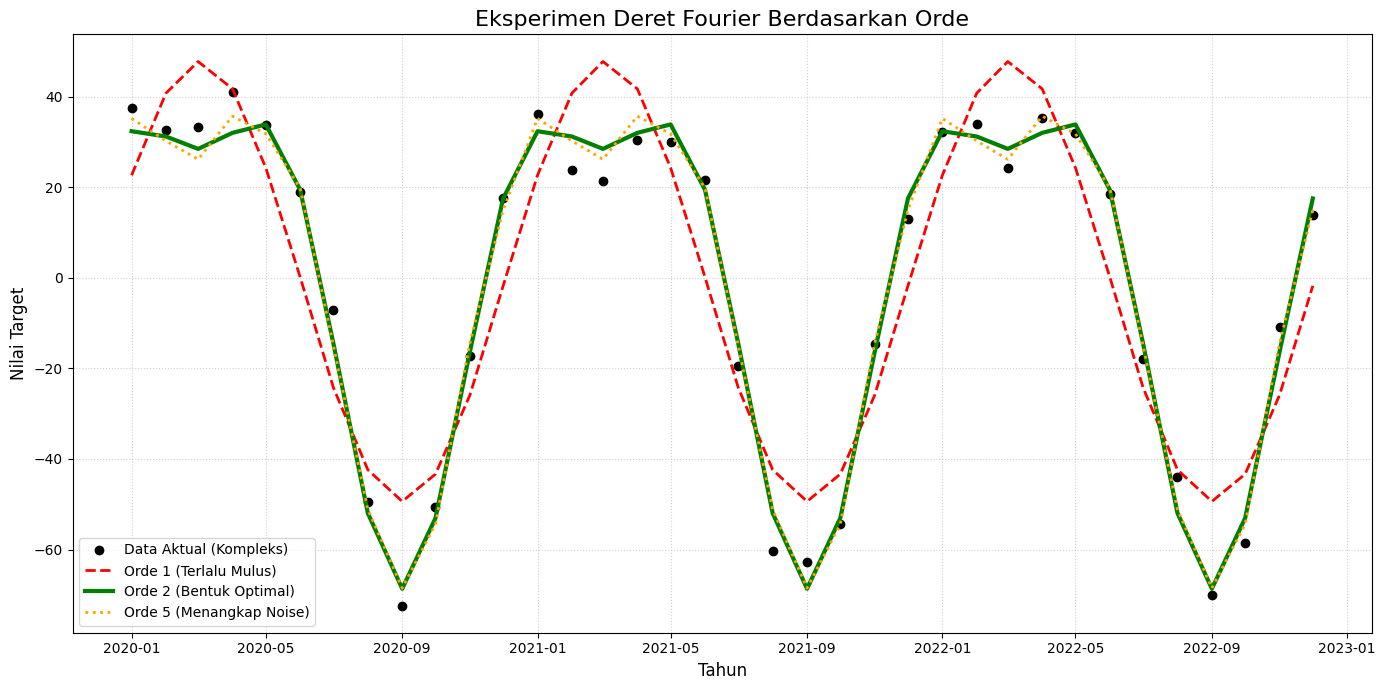

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.deterministic import DeterministicProcess, Fourier
from sklearn.linear_model import LinearRegression

np.random.seed(42)
waktu = pd.date_range('2020-01-01', periods=36, freq='MS') # 3 Tahun
t = np.arange(1, 37)

# Pola buatan: Puncak utama di pertengahan tahun, puncak kecil di akhir tahun
pola_kompleks = 50 * np.sin(2 * np.pi * t / 12) + 20 * np.cos(4 * np.pi * t / 12) + np.random.normal(0, 5, 36)
df = pd.DataFrame({'Target': pola_kompleks}, index=waktu)

def latih_fourier(orde, df_target):
    # Definisi Deret Fourier sesuai input orde
    fourier_gen = Fourier(period=12, order=orde)
    
    # Ekstraksi Matriks
    dp = DeterministicProcess(index=df_target.index, constant=True, additional_terms=[fourier_gen], drop=True)
    X_matriks = dp.in_sample()
    
    # Pelatihan Regresi
    model = LinearRegression(fit_intercept=False)
    model.fit(X_matriks, df_target['Target'])
    
    # Kembalikan hasil prediksi untuk di-plot
    return model.predict(X_matriks)

# MENGHITUNG PREDIKSI UNTUK ORDE 1, 2, DAN 5
prediksi_orde_1 = latih_fourier(orde=1, df_target=df)
prediksi_orde_2 = latih_fourier(orde=2, df_target=df)
prediksi_orde_5 = latih_fourier(orde=5, df_target=df)

# VISUALISASI KOMPARATIF
plt.figure(figsize=(14, 7))

# Plot Titik Data Aktual
plt.plot(df.index, df['Target'], color='black', marker='o', linestyle='', label='Data Aktual (Kompleks)')

# Plot Hasil Orde 1 (Terlalu Kaku / Underfitting)
plt.plot(df.index, prediksi_orde_1, color='red', linestyle='--', linewidth=2, label='Orde 1 (Terlalu Mulus)')

# Plot Hasil Orde 2 (Ideal)
plt.plot(df.index, prediksi_orde_2, color='green', linewidth=3, label='Orde 2 (Bentuk Optimal)')

# Plot Hasil Orde 5 (Terlalu Keriting / Overfitting)
plt.plot(df.index, prediksi_orde_5, color='orange', linestyle=':', linewidth=2, label='Orde 5 (Menangkap Noise)')

plt.title('Eksperimen Deret Fourier Berdasarkan Orde', fontsize=16)
plt.xlabel('Tahun', fontsize=12)
plt.ylabel('Nilai Target', fontsize=12)
plt.legend(loc='lower left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

plt.show()

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.deterministic import DeterministicProcess, Fourier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

np.random.seed(42)
total_bulan = 60 # 5 Tahun Data Historis
indeks_waktu = pd.date_range('2020-01-01', periods=total_bulan, freq='MS')

# Pembuatan rumus: Tren linier + Gelombang Sinus/Cosinus musiman + Noise
t = np.arange(1, total_bulan + 1)
tren_dasar = 100 + (1.5 * t)
gelombang_musiman = 30 * np.sin(2 * np.pi * t / 12) + 15 * np.cos(2 * np.pi * t / 12)
penumpang_aktual = tren_dasar + gelombang_musiman + np.random.normal(0, 5, total_bulan)

df_maskapai = pd.DataFrame({'Penumpang': penumpang_aktual}, index=indeks_waktu)
df_maskapai = df_maskapai.asfreq('MS')

print("=== Data Mentah Maskapai ===")
print(df_maskapai.head())

=== Data Mentah Maskapai ===
             Penumpang
2020-01-01  131.973952
2020-02-01  135.789441
2020-03-01  137.738443
2020-04-01  132.095911
2020-05-01  108.338852


In [6]:
# Definisi Fourier untuk data bulanan (1 siklus = 12 bulan), kompleksitas 2 orde (4 kolom)
fourier_terms = Fourier(period=12, order=2)

# Menggabungkan Tren Linier, Tren Kuadratik, dan Fourier dalam satu proses
dp_terpadu = DeterministicProcess(
    index=df_maskapai.index,
    constant=True,
    order=2, # Tren kuadratik (trend, trend_squared)
    additional_terms=[fourier_terms],
    drop=True
)

X_fitur = dp_terpadu.in_sample()
y_target = df_maskapai['Penumpang']

print("\n=== Matriks (Tren + Fourier) ===")
print(X_fitur.head())


=== Matriks (Tren + Fourier) ===
            const  trend  trend_squared  sin(1,12)     cos(1,12)  \
2020-01-01    1.0    1.0            1.0   0.000000  1.000000e+00   
2020-02-01    1.0    2.0            4.0   0.500000  8.660254e-01   
2020-03-01    1.0    3.0            9.0   0.866025  5.000000e-01   
2020-04-01    1.0    4.0           16.0   1.000000  6.123234e-17   
2020-05-01    1.0    5.0           25.0   0.866025 -5.000000e-01   

               sin(2,12)  cos(2,12)  
2020-01-01  0.000000e+00        1.0  
2020-02-01  8.660254e-01        0.5  
2020-03-01  8.660254e-01       -0.5  
2020-04-01  1.224647e-16       -1.0  
2020-05-01 -8.660254e-01       -0.5  


In [ ]:
langkah_uji = 12
X_train = X_fitur.iloc[:-langkah_uji]
X_test = X_fitur.iloc[-langkah_uji:]
y_train = y_target.iloc[:-langkah_uji]
y_test = y_target.iloc[-langkah_uji:]

model_musiman = LinearRegression(fit_intercept=False)
model_musiman.fit(X_train, y_train)

# Evaluasi Data Ujian
prediksi_uji = model_musiman.predict(X_test)
error_mae = mean_absolute_error(y_test, prediksi_uji)

print(f"\n=== Hasil Validasi Model ===")
print(f"Rata-rata Kesalahan (MAE): {error_mae:.2f} Penumpang")


=== Hasil Validasi Model ===
Rata-rata Kesalahan (MAE): 3.34 Penumpang


In [8]:
horizon_masa_depan = 24

# Pustaka statsmodels secara otomatis merumuskan perpanjangan tren dan fourier ke masa depan
X_masa_depan = dp_terpadu.out_of_sample(steps=horizon_masa_depan)

# Prediksi murni tanpa data target
prediksi_masa_depan = model_musiman.predict(X_masa_depan)

df_hasil_forecast = pd.DataFrame({
    'Prediksi_Penumpang': np.round(prediksi_masa_depan, 0)
}, index=X_masa_depan.index)

print(df_hasil_forecast.head())

            Prediksi_Penumpang
2025-01-01               222.0
2025-02-01               229.0
2025-03-01               227.0
2025-04-01               219.0
2025-05-01               206.0


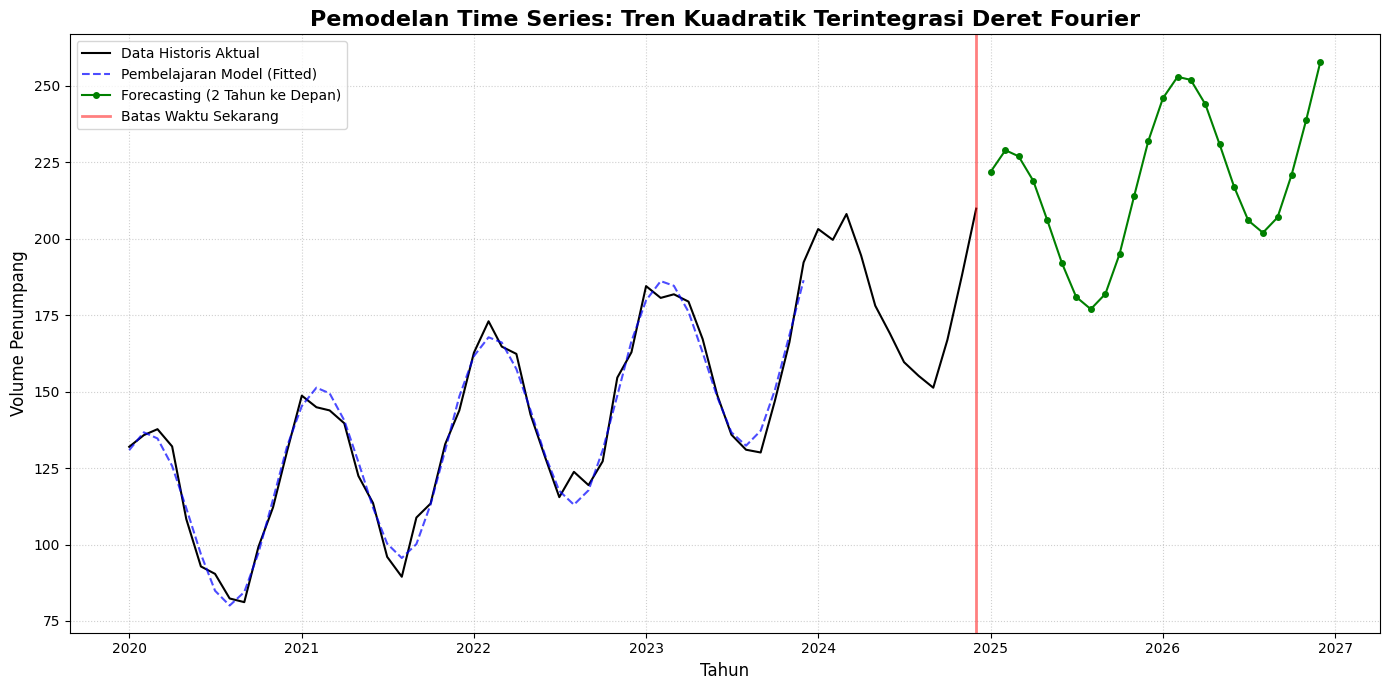

In [9]:
# VISUALISASI KESELURUHAN
plt.figure(figsize=(14, 7))

# Plot Data Historis
plt.plot(df_maskapai.index, 
         df_maskapai['Penumpang'], 
         color='black', label='Data Historis Aktual')

# Plot Garis Fit Model (Pembelajaran Masa Lalu)
plt.plot(X_train.index, model_musiman.predict(X_train), 
         color='blue', linestyle='--', alpha=0.7, label='Pembelajaran Model (Fitted)')

# Plot True Forecasting Masa Depan
plt.plot(df_hasil_forecast.index, df_hasil_forecast['Prediksi_Penumpang'], 
         color='green', marker='o', markersize=4, label='Forecasting (2 Tahun ke Depan)')

# Estetika Grafik
plt.axvline(x=df_maskapai.index[-1], color='red', 
            linestyle='-', linewidth=2, alpha=0.5, label='Batas Waktu Sekarang')
plt.title('Pemodelan Time Series: Tren Kuadratik Terintegrasi Deret Fourier', fontsize=16, fontweight='bold')
plt.xlabel('Tahun', fontsize=12)
plt.ylabel('Volume Penumpang', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

plt.show()

Assignment

In [10]:
data = pd.read_csv("Walmart_Sales.csv")
data

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...,...,...
6430,45,28-09-2012,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,05-10-2012,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,12-10-2012,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,19-10-2012,718125.53,0,56.47,3.969,192.330854,8.667


Memuat dan memproses data...
Mengekstraksi fitur Tren dan Fourier...
Melatih model Regresi Linier...

=== HASIL EVALUASI ===
Mean Absolute Error (MAE): 1,930,176.18

Melakukan forecasting dan membuat grafik...


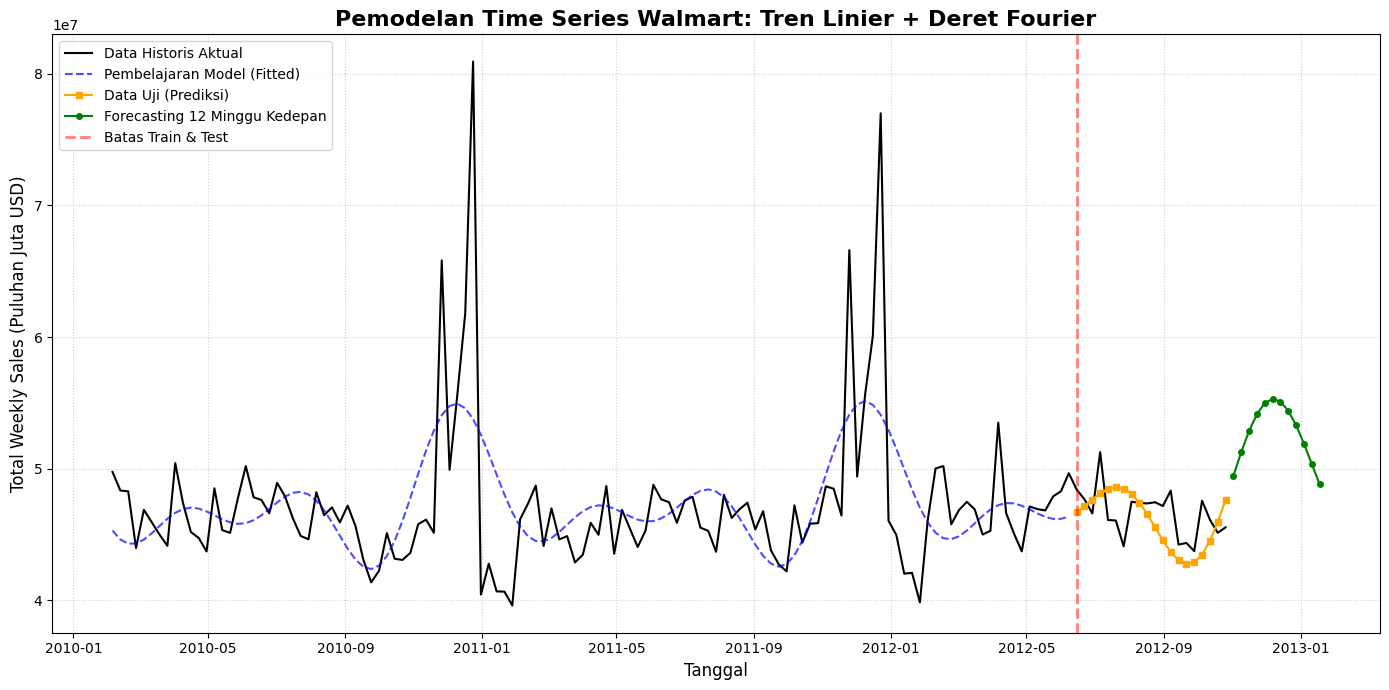

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.deterministic import DeterministicProcess, Fourier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# ==========================================
# 1. PERSIAPAN DATA (DATA PREPROCESSING)
# ==========================================
print("Memuat dan memproses data...")
df = pd.read_csv('Walmart_Sales.csv')

# Format tanggal pada dataset adalah DD-MM-YYYY
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')

# Agregasi: Menjumlahkan Weekly_Sales dari seluruh toko berdasarkan Tanggal
df_agg = df.groupby('Date')['Weekly_Sales'].sum().reset_index()
df_agg = df_agg.set_index('Date').sort_index()

# Menetapkan frekuensi indeks menjadi Mingguan pada hari Jumat
df_agg = df_agg.asfreq('W-FRI')

# ==========================================
# 2. EKSTRAKSI FITUR (FEATURE EXTRACTION)
# ==========================================
print("Mengekstraksi fitur Tren dan Fourier...")
# Komponen Fourier untuk siklus 1 Tahun (52.14 minggu) dengan Orde 3
fourier_terms = Fourier(period=52.14, order=3)

# Membangun matriks fitur Tren Linier dan Fourier
dp_terpadu = DeterministicProcess(
    index=df_agg.index,
    constant=True,
    order=1, # Tren Linier
    additional_terms=[fourier_terms],
    drop=True
)

X_fitur = dp_terpadu.in_sample()
y_target = df_agg['Weekly_Sales']

# ==========================================
# 3. PEMBAGIAN DATA (DATA SPLITTING)
# ==========================================
langkah_uji = 20 # 20 Minggu terakhir untuk Data Uji

# Time-based splitting (Tanpa Shuffle)
X_train = X_fitur.iloc[:-langkah_uji]
X_test = X_fitur.iloc[-langkah_uji:]
y_train = y_target.iloc[:-langkah_uji]
y_test = y_target.iloc[-langkah_uji:]

# ==========================================
# 4. PELATIHAN MODEL (MODELING)
# ==========================================
print("Melatih model Regresi Linier...")
# fit_intercept=False karena fitur konstan (const) sudah ada dari DeterministicProcess
model_musiman = LinearRegression(fit_intercept=False)
model_musiman.fit(X_train, y_train)

# ==========================================
# 5. EVALUASI (EVALUATION)
# ==========================================
prediksi_uji = model_musiman.predict(X_test)
error_mae = mean_absolute_error(y_test, prediksi_uji)

print("\n=== HASIL EVALUASI ===")
print(f"Mean Absolute Error (MAE): {error_mae:,.2f}")

# ==========================================
# 6. FORECASTING & VISUALISASI
# ==========================================
print("\nMelakukan forecasting dan membuat grafik...")
langkah_depan = 12 # Ramalan 12 minggu ke depan

# Ekstraksi fitur waktu menembus batas data masa lalu
X_masa_depan = dp_terpadu.out_of_sample(steps=langkah_depan)
prediksi_masa_depan = model_musiman.predict(X_masa_depan)

# Konfigurasi Grafik Visualisasi
plt.figure(figsize=(14, 7))

# Plot 1: Data Aktual & Area Pembelajaran (Training)
plt.plot(df_agg.index, df_agg['Weekly_Sales'], color='black', label='Data Historis Aktual')
plt.plot(X_train.index, model_musiman.predict(X_train), color='blue', linestyle='--', alpha=0.7, label='Pembelajaran Model (Fitted)')

# Plot 2: Area Prediksi (Testing)
plt.plot(X_test.index, prediksi_uji, color='orange', marker='s', markersize=4, label='Data Uji (Prediksi)')

# Plot 3: Area Peramalan (Forecasting)
plt.plot(X_masa_depan.index, prediksi_masa_depan, color='green', marker='o', markersize=4, label='Forecasting 12 Minggu Kedepan')

# Plot 4: Garis Batas Waktu
plt.axvline(x=X_test.index[0], color='red', linestyle='--', linewidth=2, alpha=0.5, label='Batas Train & Test')

# Estetika Grafik
plt.title('Pemodelan Time Series Walmart: Tren Linier + Deret Fourier', fontsize=16, fontweight='bold')
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('Total Weekly Sales (Puluhan Juta USD)', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Menampilkan grafik
plt.show()